# 06 — Shapley Value Analysis

Extracts and visualises SHAP feature importance for four bubble-detection label variants:
`gsadf_v1_period`, `gsadf_updown_period`, `lppls_0.01_period`, and `cusum_smoothed`.

Each section contains: (1) a price chart with bubble periods highlighted, (2) SHAP plots using **LASSO** — the single model with the highest mean F1 across all metals on `gsadf_v1_period` — applied consistently across all variants and metals, and (3) SHAP plots using the **best model per metal** for each variant.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_recall_curve
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import os

os.makedirs('../outputs', exist_ok=True)

# ── Load all_labels.csv (GSADF + LPPLS variants) ─────────────────────────
df = pd.read_csv('../outputs/all_labels.csv')
df['Date'] = pd.to_datetime(df['Date'])

# ── Load and remap CUSUM flags (CODALY_ → Cobalt_ naming) ────────────────
cusum_raw = pd.read_csv('../R/cusum_flags.csv', index_col=0)
cusum_raw['Date'] = pd.to_datetime(cusum_raw['Date'])
REMAP = {'CODALY': 'Cobalt', 'CUDALY': 'Copper', 'LIDALY': 'Lithium', 'NIDALY': 'Nickel'}
for ticker, metal in REMAP.items():
    df = df.merge(
        cusum_raw[['Date', f'{ticker}_cusum_smoothed']].rename(
            columns={f'{ticker}_cusum_smoothed': f'{metal}_cusum_smoothed'}),
        on='Date', how='left'
    )
    df[f'{metal}_cusum_smoothed'] = df[f'{metal}_cusum_smoothed'].fillna(0).astype(int)

METALS = {'Cobalt': 'CODALY', 'Copper': 'CUDALY', 'Lithium': 'LIDALY', 'Nickel': 'NIDALY'}

# The 4 variants we analyse in this notebook
FOCUS_VARIANTS = ['gsadf_v1_period', 'gsadf_updown_period', 'lppls_0.01_period', 'cusum_smoothed']

# Best single model across all metals on gsadf_v1_period (from 02_model_training)
GLOBAL_BEST_MODEL = 'LASSO'

# Best model per (variant, metal) from 02_model_training results
BEST_PER_COMBO = {
    'gsadf_v1_period':    {'Cobalt': 'CatBoost', 'Copper': 'CatBoost',  'Lithium': 'LASSO',    'Nickel': 'LASSO'},
    'gsadf_updown_period':{'Cobalt': 'RF',        'Copper': 'LightGBM', 'Lithium': 'LASSO',    'Nickel': 'LASSO'},
    'lppls_0.01_period':  {'Cobalt': 'LASSO',     'Copper': 'CatBoost', 'Lithium': 'XGBoost',  'Nickel': 'LASSO'},
    'cusum_smoothed':     {'Cobalt': 'LASSO',     'Copper': 'LASSO',    'Lithium': 'LASSO',    'Nickel': 'LASSO'},
}

VARIANT_COLORS = {
    'gsadf_v1_period':     '#e67e22',
    'gsadf_updown_period': '#17a589',
    'lppls_0.01_period':   '#8e44ad',
    'cusum_smoothed':      '#c0392b',
}

print(f'Data: {len(df)} rows, label columns loaded for: {FOCUS_VARIANTS}')
for v in FOCUS_VARIANTS:
    days = sum(df[f'Cobalt_{v}'].sum() for _ in [0])
    check = [f'{m}_{v}' in df.columns for m in METALS]
    print(f'  {v}: all columns present = {all(check)}')


Data: 2152 rows, label columns loaded for: ['gsadf_v1_period', 'gsadf_updown_period', 'lppls_0.01_period', 'cusum_smoothed']
  gsadf_v1_period: all columns present = True
  gsadf_updown_period: all columns present = True
  lppls_0.01_period: all columns present = True
  cusum_smoothed: all columns present = True


In [25]:
# ═══════════════════════════════════════════════════════════════════════════
#  Shared helpers — feature engineering, model building, SHAP computation
# ═══════════════════════════════════════════════════════════════════════════

def prepare_features(target_metal, label_variant, df_master):
    """Build lagged feature matrix for a single metal; no look-ahead by design.

    Only the TARGET metal's own price series is used — other metals' prices
    and their bubble-label lags are excluded so that SHAP attributions remain
    specific to that metal.
    """
    target_col    = f'{target_metal}_{label_variant}'
    target_ticker = METALS[target_metal]           # e.g. 'CODALY' for Cobalt
    all_tickers   = set(METALS.values())           # {'CODALY','CUDALY','LIDALY','NIDALY'}

    # Macro columns: everything that is not a date, not any metal price ticker,
    # and not a bubble-label column of any metal
    macro_cols = [
        c for c in df_master.columns
        if c != 'Date'
        and c not in all_tickers
        and not any(c.startswith(m + '_') for m in METALS)
    ]

    # Feature pool: only the target metal's own price + all macro series
    num_cols = [target_ticker] + macro_cols

    out = pd.DataFrame({'Date': df_master['Date']})
    for col in num_cols:
        safe = df_master[col].clip(lower=0.001)
        lr = np.log(safe).diff()
        out[col + '_Ret_L1']   = lr.shift(1)
        out[col + '_Vol10_L1'] = lr.rolling(10).std().shift(1)
    for col in num_cols:
        out[col + '_Level_L1'] = df_master[col].shift(1)

    out['Target'] = df_master[target_col].astype(int)
    return out.dropna().reset_index(drop=True)


def build_model(mname):
    """Return a default-hyperparameter model instance."""
    if mname == 'LASSO':
        return LogisticRegression(penalty='l1', solver='saga', C=0.1,
                                   max_iter=10000, random_state=42)
    if mname == 'LightGBM':
        return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                   num_leaves=31, verbose=-1, random_state=42)
    if mname == 'XGBoost':
        return xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                  eval_metric='auc', verbosity=0, random_state=42)
    if mname == 'RF':
        return RandomForestClassifier(n_estimators=300, max_depth=6,
                                       random_state=42)
    if mname == 'CatBoost':
        return CatBoostClassifier(iterations=300, learning_rate=0.05,
                                   depth=4, verbose=0, random_state=42)
    raise ValueError(f'Unknown model: {mname}')


def fit_and_shap(metal, variant, model_name):
    """
    Train model on 80% of data, compute SHAP values on last 20%.
    Returns (shap_values_2d, feature_names, X_test_unscaled, model).

    shap_values_2d is always shape (n_test, n_features) — class-1 slice for
    tree models, direct output for LinearExplainer.
    X_test_unscaled is the original (unscaled) feature DataFrame, used for
    coloring beeswarm plots by true feature value.
    """
    feat = prepare_features(metal, variant, df)
    X = feat.drop(columns=['Date', 'Target'])
    y = feat['Target']

    split = int(len(feat) * 0.80)
    X_tr, X_te = X.iloc[:split], X.iloc[split:]
    y_tr = y.iloc[:split]
    X_te_orig = X_te.reset_index(drop=True)   # always keep unscaled for coloring

    model = build_model(model_name)
    if model_name == 'LASSO':
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)
        model.fit(X_tr_s, y_tr)
        explainer = shap.LinearExplainer(model, X_te_s,
                                          feature_perturbation='interventional')
        sv = explainer.shap_values(X_te_s)
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.array(sv)
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        return sv, X.columns.tolist(), X_te_orig, model
    else:
        model.fit(X_tr, y_tr)
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_te)
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.array(sv)
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        return sv, X.columns.tolist(), X_te_orig, model


def friendly_name(col):
    """Convert raw feature name to a readable label for plots."""
    SERIES_MAP = {
        'CODALY': 'Cobalt',  'CUDALY': 'Copper', 'LIDALY': 'Lithium',
        'NIDALY': 'Nickel',  'OIL_WTI': 'WTI Oil', 'GAS_HHUB': 'HH Gas',
        'USD_INDEX': 'DXY',  'VIX': 'VIX',       'YIELD_10Y': '10Y Yield',
        'GOLD_FUT': 'Gold',  'MSCI_ETF': 'MSCI World', 'MSCI_EM': 'MSCI EM',
        'SP500': 'S&P 500',  'QCLN': 'Clean Energy ETF',
        'C_CHR': 'China Chromium', 'C_US': 'Peabody Energy',
    }
    for k, v in SERIES_MAP.items():
        if col.startswith(k):
            suffix = col[len(k):]
            suffix = (suffix.replace('_Ret_L1', ' ret')
                            .replace('_Vol10_L1', ' vol')
                            .replace('_Level_L1', ' lvl')
                            .replace('_L1', ' lag1'))
            return v + suffix
    return col


print('Helpers ready.')


Helpers ready.


In [41]:
# ─── Bubble chart helper ────────────────────────────────────────────────────

def plot_bubbles_2x2(variant, color, save_path):
    """2×2 grid: price + shaded bubble periods for all 4 metals."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
    dates = df['Date']
    for ax, (metal, col) in zip(axes.flat, METALS.items()):
        ax.plot(dates, df[col], color='black', lw=0.8)
        flag = df[f'{metal}_{variant}'].values
        in_b = False
        for i in range(len(flag)):
            if flag[i] == 1 and not in_b:
                s = dates.iloc[i]; in_b = True
            elif (flag[i] == 0 or i == len(flag) - 1) and in_b:
                ax.axvspan(s, dates.iloc[i], color=color, alpha=0.35)
                in_b = False
        ax.set_title(metal, fontsize=10, fontweight='bold')
        ax.set_ylabel('USD/t', fontsize=8)
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.2)
    fig.autofmt_xdate(rotation=45)
    plt.suptitle(variant.replace('_', ' '), fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_path}')


# ─── Beeswarm helpers ────────────────────────────────────────────────────────

_BEESWARM_CMAP = plt.cm.coolwarm   # blue = low feature value, red = high
_SHAP_ZERO_TOL = 1e-9              # features with mean|SHAP| below this are skipped


def _beeswarm_row_jitter(shap_col, max_y=0.4):
    """
    Compute y-offsets for one beeswarm row by binning along x and spreading
    each bin symmetrically in y (proportional to sqrt of bin occupancy).
    """
    n = len(shap_col)
    if n <= 1:
        return np.zeros(n)
    vmin, vmax = shap_col.min(), shap_col.max()
    if vmin == vmax:
        return np.zeros(n)

    n_bins = max(25, int(n ** 0.55))
    edges  = np.linspace(vmin, vmax + 1e-12, n_bins + 1)
    bin_id = np.clip(np.digitize(shap_col, edges) - 1, 0, n_bins - 1)
    avg_occ = n / n_bins

    y = np.zeros(n)
    for b in range(n_bins):
        pts = np.where(bin_id == b)[0]
        k   = len(pts)
        if k == 0:
            continue
        if k == 1:
            y[pts[0]] = 0.0
        else:
            hw = min(max_y, max_y * np.sqrt(k / max(avg_occ, 1)))
            y[pts] = np.linspace(-hw, hw, k)
    return y


def _shap_beeswarm_ax(ax, sv, feat_names, X_te, top_n=12):
    """
    Draw a beeswarm SHAP plot on *ax*.

    - Y-axis  : up to top_n features ranked by mean |SHAP|, highest at top.
                Features where every observation has SHAP ≈ 0 (e.g. LASSO
                zeroed-out coefficients) are excluded automatically.
    - X-axis  : signed SHAP value — positive pushes toward bubble prediction.
    - Dots    : all test observations, coloured by normalised feature value
                (blue = low, red = high).
    - Tick    : short vertical black line at the per-feature mean SHAP.
    """
    sv         = np.array(sv)
    feat_names = list(feat_names)
    X_arr = X_te.values.astype(float) if hasattr(X_te, 'values') else np.asarray(X_te, float)

    mean_abs = np.abs(sv).mean(axis=0)

    # Select top_n features that have at least some non-zero SHAP signal
    ranked = np.argsort(mean_abs)[::-1]           # best first
    active = [i for i in ranked if mean_abs[i] > _SHAP_ZERO_TOL]
    top_idx = active[:top_n][::-1]                # reverse so highest is at top of plot

    if len(top_idx) == 0:
        ax.text(0.5, 0.5, 'All SHAP values ≈ 0\n(model has no active features)',
                ha='center', va='center', transform=ax.transAxes, fontsize=8)
        return

    half_tick = 0.36   # half-height of the mean tick line

    for row, feat_i in enumerate(top_idx):
        shap_col = sv[:, feat_i]
        feat_col = X_arr[:, feat_i]

        # normalise feature values to [0,1] via 5th–95th percentile
        lo, hi = np.nanpercentile(feat_col, 5), np.nanpercentile(feat_col, 95)
        fv_norm = np.clip((feat_col - lo) / (hi - lo + 1e-12), 0, 1)

        jitter = _beeswarm_row_jitter(shap_col, max_y=0.38)
        ax.scatter(shap_col, row + jitter,
                   c=_BEESWARM_CMAP(fv_norm),
                   s=7, alpha=0.65, linewidths=0,
                   rasterized=True, zorder=2)

        # Mean: short vertical tick line spanning the row's y-band
        m = shap_col.mean()
        ax.vlines(m, row - half_tick, row + half_tick,
                  colors='black', linewidth=1.5, zorder=5)

    labels = [friendly_name(feat_names[int(i)]) for i in top_idx]
    ax.set_yticks(range(len(top_idx)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.axvline(0, color='#666666', lw=0.7, linestyle='--', zorder=1)
    ax.set_xlabel('SHAP value  →  impact on bubble probability', fontsize=7.5)
    ax.tick_params(axis='x', labelsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', alpha=0.15, lw=0.5)
    ax.set_ylim(-0.7, len(top_idx) - 0.3)


# ─── 2×2 SHAP panel functions ────────────────────────────────────────────────

def plot_shap_beeswarm_panel(variant, model_name, save_path, top_n=12):
    """2×2 beeswarm panel (fixed model, one subplot per metal)."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    for ax, (metal, _) in zip(axes.flat, METALS.items()):
        try:
            sv, feat_names, X_te, _ = fit_and_shap(metal, variant, model_name)
        except Exception as e:
            ax.text(0.5, 0.5, f'Error:\n{e}', ha='center', va='center',
                    transform=ax.transAxes, fontsize=7)
            ax.set_title(metal, fontsize=9); continue
        _shap_beeswarm_ax(ax, sv, feat_names, X_te, top_n)
        ax.set_title(metal, fontsize=10, fontweight='bold')
    plt.suptitle(f'{variant.replace("_", " ")}  ·  {model_name}',
                 fontsize=11, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_path}')


def plot_shap_best_per_metal(variant, color, save_path, top_n=12):
    """2×2 beeswarm panel (best model per metal)."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    for ax, (metal, _) in zip(axes.flat, METALS.items()):
        best_m = BEST_PER_COMBO[variant][metal]
        try:
            sv, feat_names, X_te, _ = fit_and_shap(metal, variant, best_m)
        except Exception as e:
            ax.text(0.5, 0.5, str(e), ha='center', va='center',
                    transform=ax.transAxes, fontsize=7)
            ax.set_title(f'{metal}', fontsize=9); continue
        _shap_beeswarm_ax(ax, sv, feat_names, X_te, top_n)
        ax.set_title(f'{metal}  [{best_m}]', fontsize=10, fontweight='bold')
    plt.suptitle(f'{variant.replace("_", " ")}  ·  best model per metal',
                 fontsize=11, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_path}')


print('Plot helpers ready.')


Plot helpers ready.


---
## Section 1 — `gsadf_v1_period`

`gsadf_v1_period` uses the alternative GSADF bubble-dating algorithm (V1 specification) with morphological post-processing — gap-bridging ≤ 5 days and minimum episode duration ≥ 3 days. It captures statistically explosive price regimes that trend upward, filtering out very short or isolated signals. LASSO is the single model with the highest mean F1 across all four metals on this variant (mean F1 = 0.437).

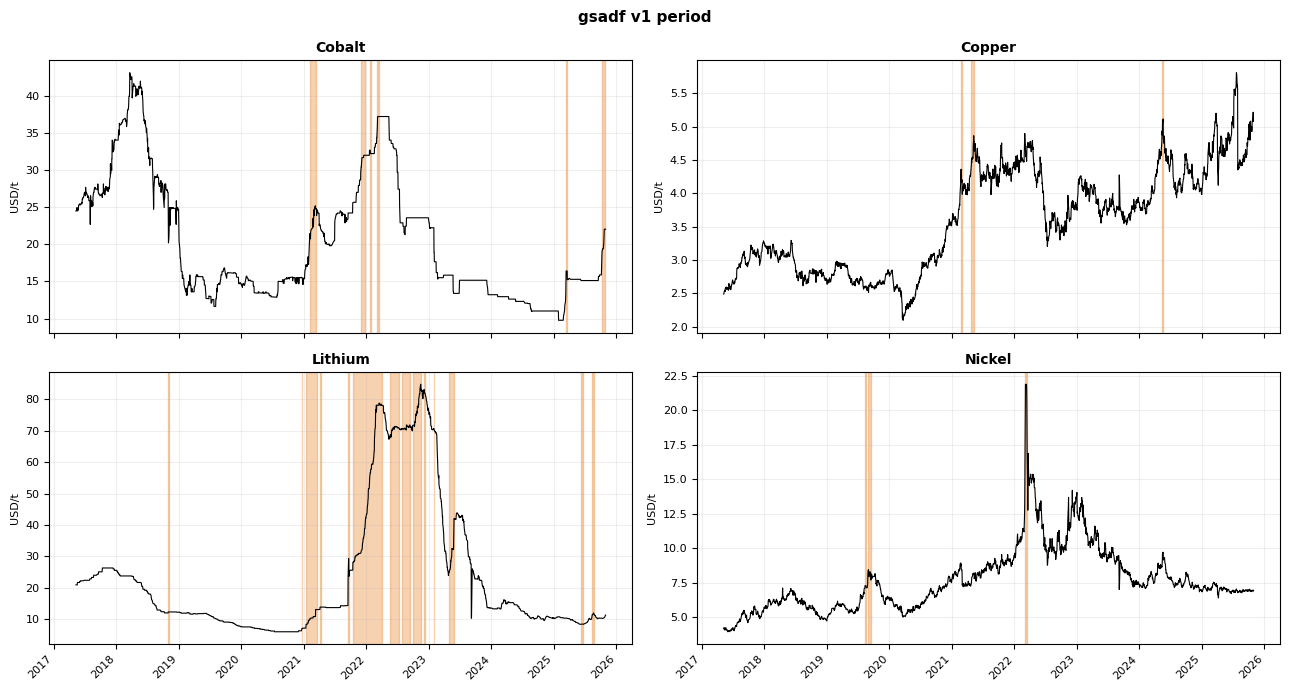

Saved → ../outputs/06_gsadf_v1_period_bubbles.png


In [43]:
V = 'gsadf_v1_period'
C = VARIANT_COLORS[V]

# 1a. Price chart with bubble periods
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on gsadf_v1_period × 4 metals ...


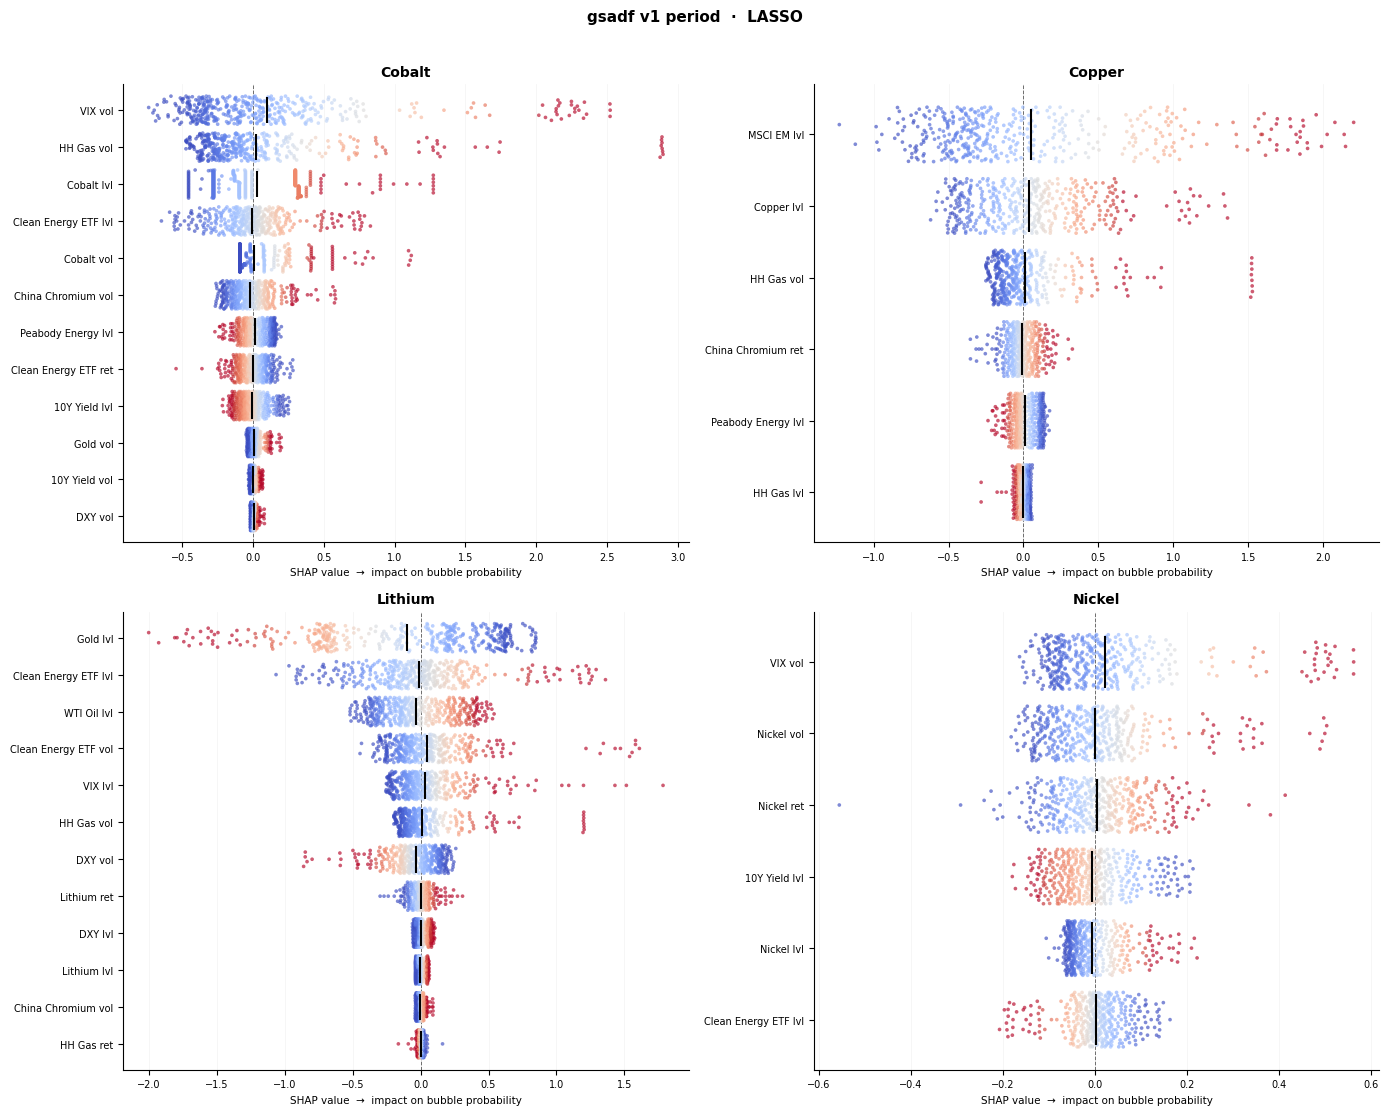

Saved → ../outputs/06_gsadf_v1_period_shap_lasso_global.png


In [44]:
# 1b. SHAP — global-best model (LASSO) applied to all metals × all 4 focus variants
# This gives a consistent cross-variant comparison using one model type.
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}_global.png')


Computing SHAP: best-per-metal on gsadf_v1_period ...


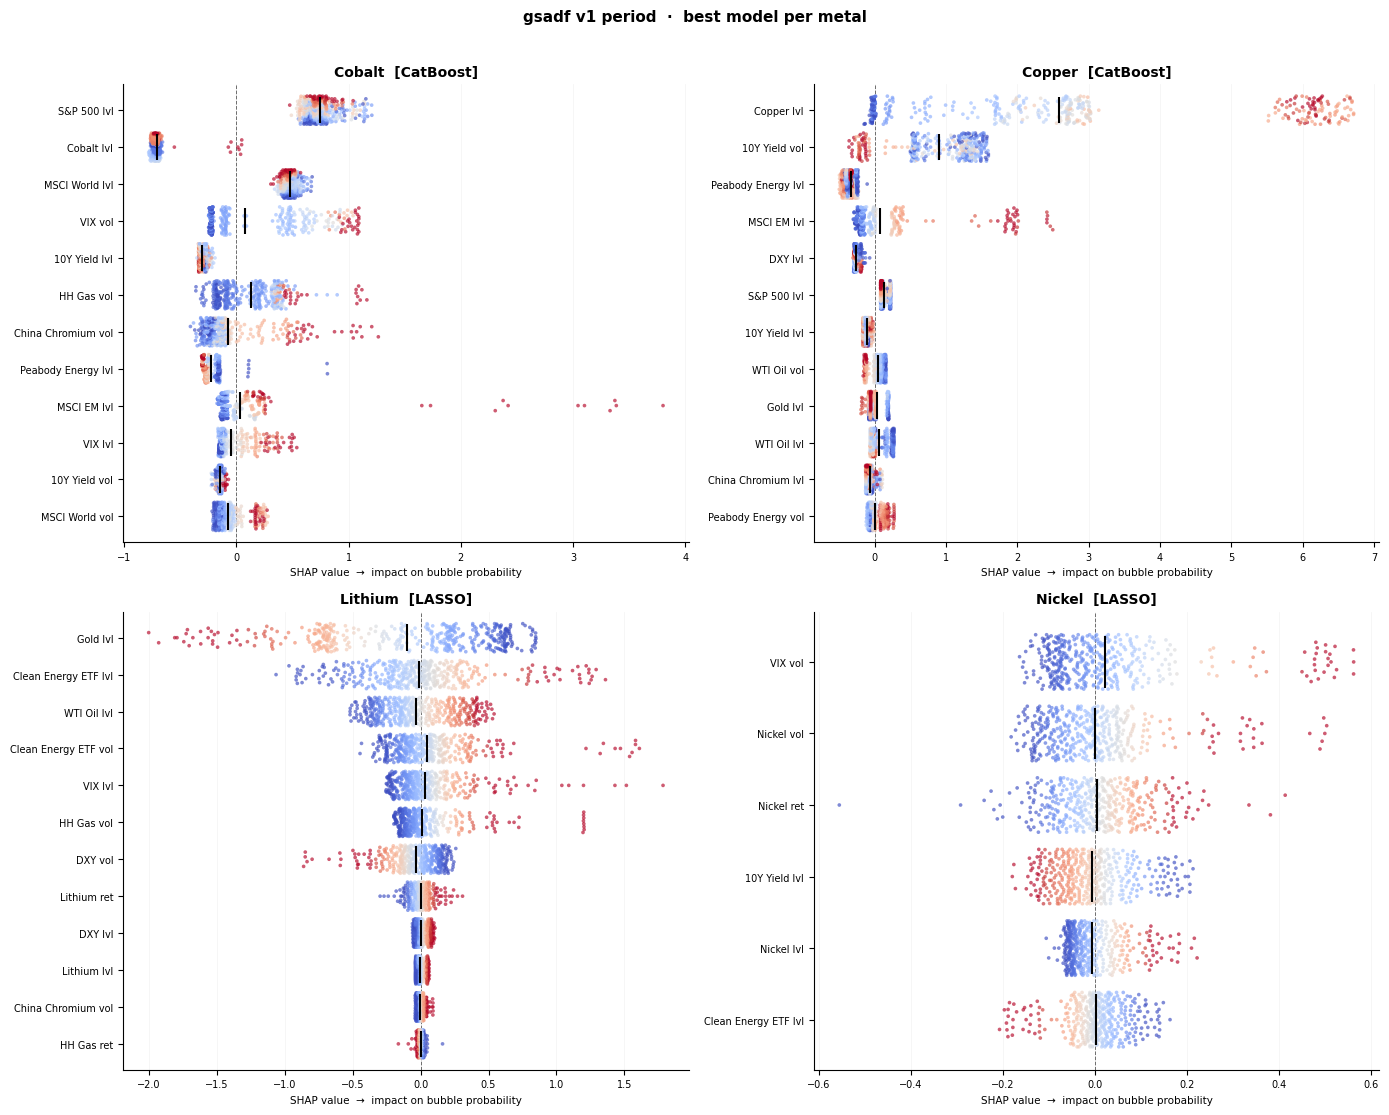

Saved → ../outputs/06_gsadf_v1_period_shap_best_per_metal.png


In [45]:
# 1c. SHAP — best model per metal for this variant
print(f'Computing SHAP: best-per-metal on {V} ...')
plot_shap_best_per_metal(V, C, f'../outputs/06_{V}_shap_best_per_metal.png')


---
## Section 2 — `gsadf_updown_period`

`gsadf_updown_period` retains all GSADF-datestamped episodes regardless of price direction — unlike the OLS/V1 variants, it includes both the bubble inflation and the crash phase. Post-processing (gap-bridging and minimum duration) is applied identically. This broader labelling led to the best overall model performance on Lithium and Nickel (F1 0.75 and 0.90 respectively).

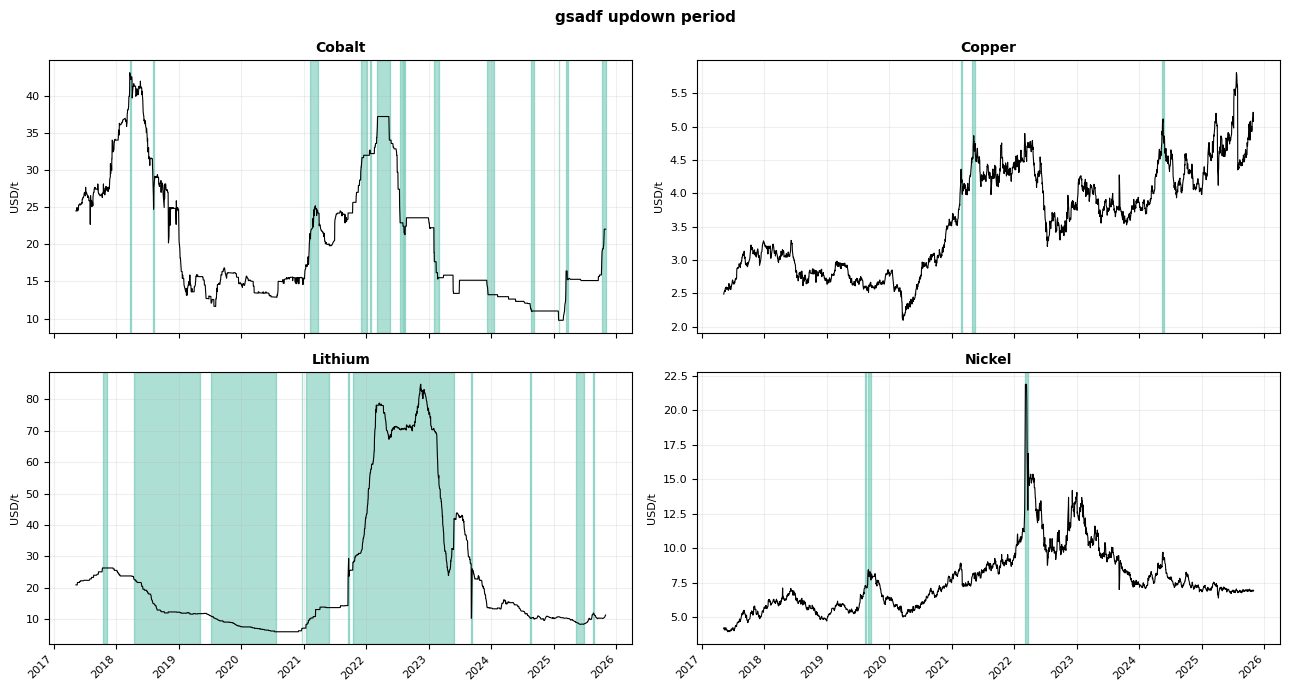

Saved → ../outputs/06_gsadf_updown_period_bubbles.png


In [46]:
V = 'gsadf_updown_period'
C = VARIANT_COLORS[V]

# 2a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on gsadf_updown_period × 4 metals ...


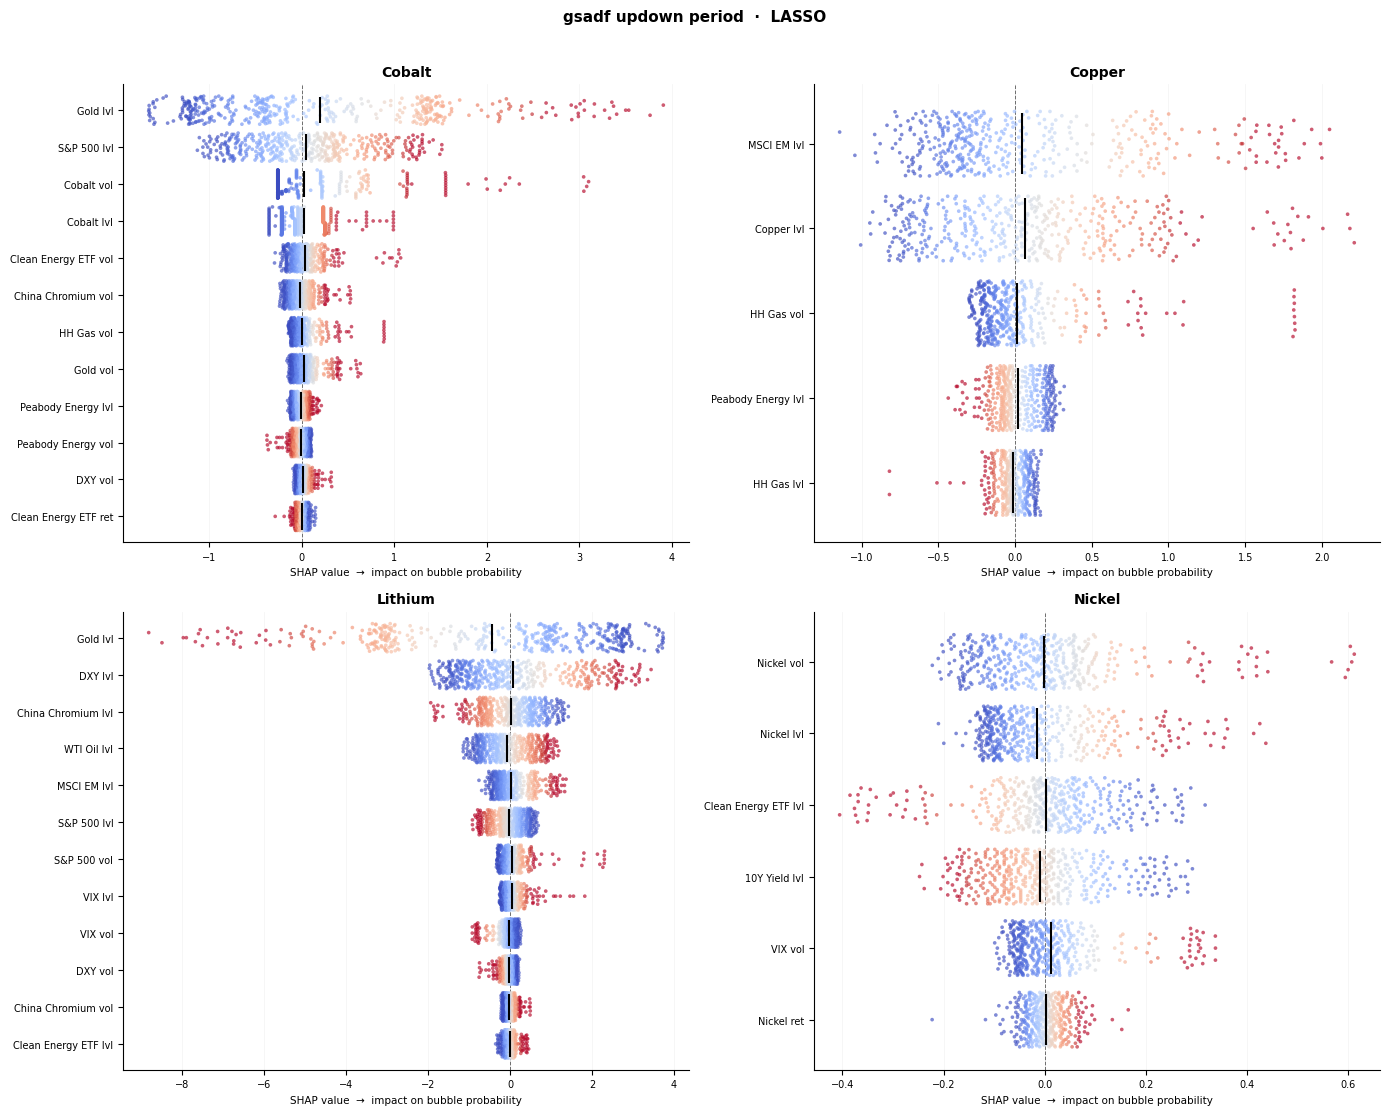

Saved → ../outputs/06_gsadf_updown_period_shap_lasso_global.png


In [47]:
# 2b. SHAP — global-best model (LASSO)
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}_global.png')


Computing SHAP: best-per-metal on gsadf_updown_period ...


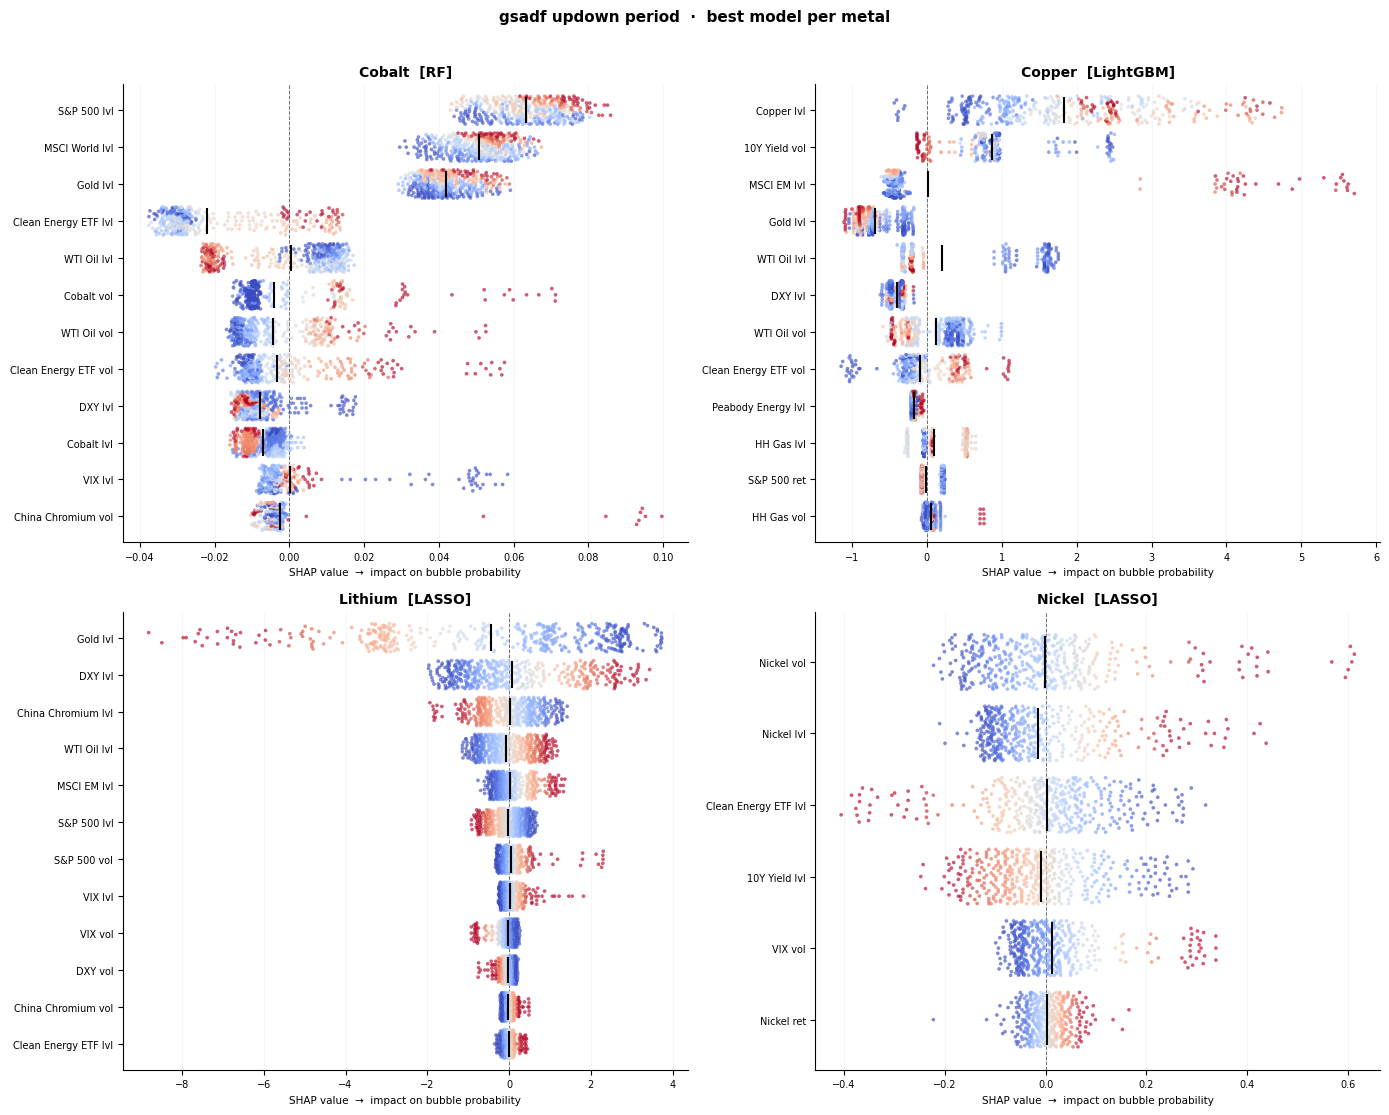

Saved → ../outputs/06_gsadf_updown_period_shap_best_per_metal.png


In [48]:
# 2c. SHAP — best model per metal
print(f'Computing SHAP: best-per-metal on {V} ...')
plot_shap_best_per_metal(V, C, f'../outputs/06_{V}_shap_best_per_metal.png')


---
## Section 3 — `lppls_0.01_period`

`lppls_0.01_period` is the most permissive LPPLS variant: it flags days where the smoothed LPPLS confidence score exceeds just 1%, then applies the trend filter and morphological post-processing. The low threshold captures many more potential bubble days than the 0.10 or 0.20 variants, at the cost of more false positives. For Cobalt this is the top-performing variant overall (AUC 0.909 with LASSO).

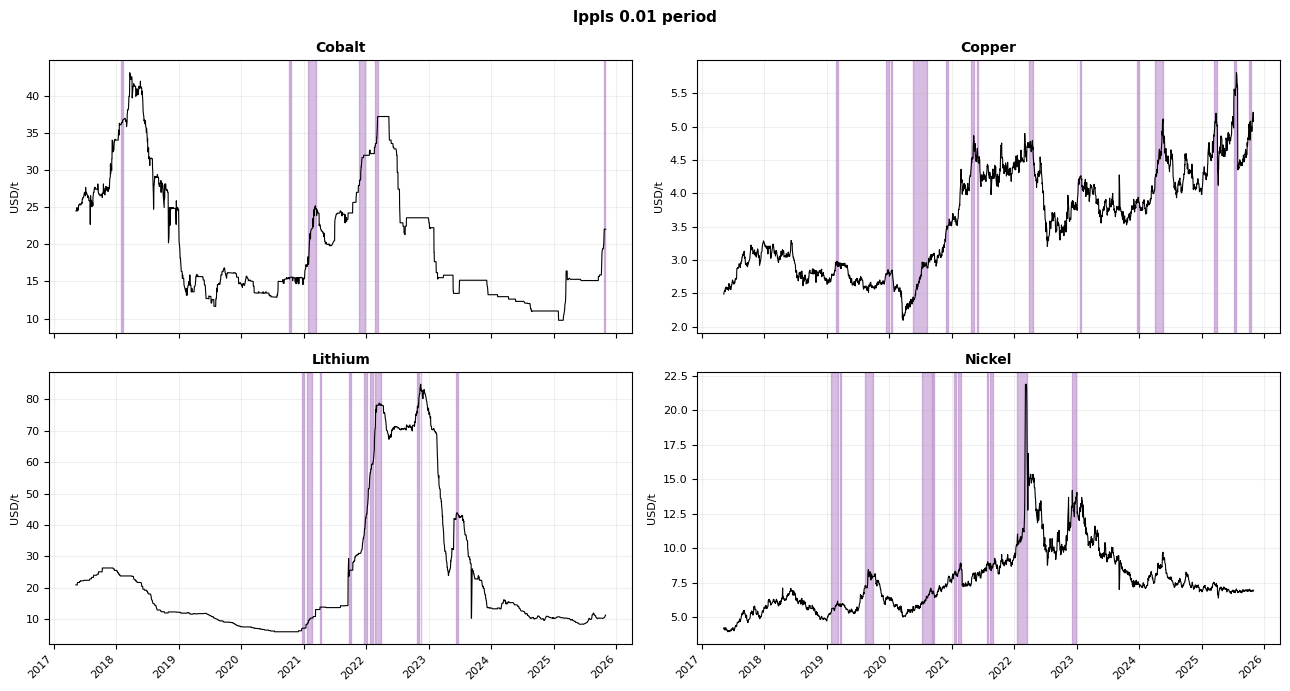

Saved → ../outputs/06_lppls_0.01_period_bubbles.png


In [49]:
V = 'lppls_0.01_period'
C = VARIANT_COLORS[V]

# 3a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on lppls_0.01_period × 4 metals ...


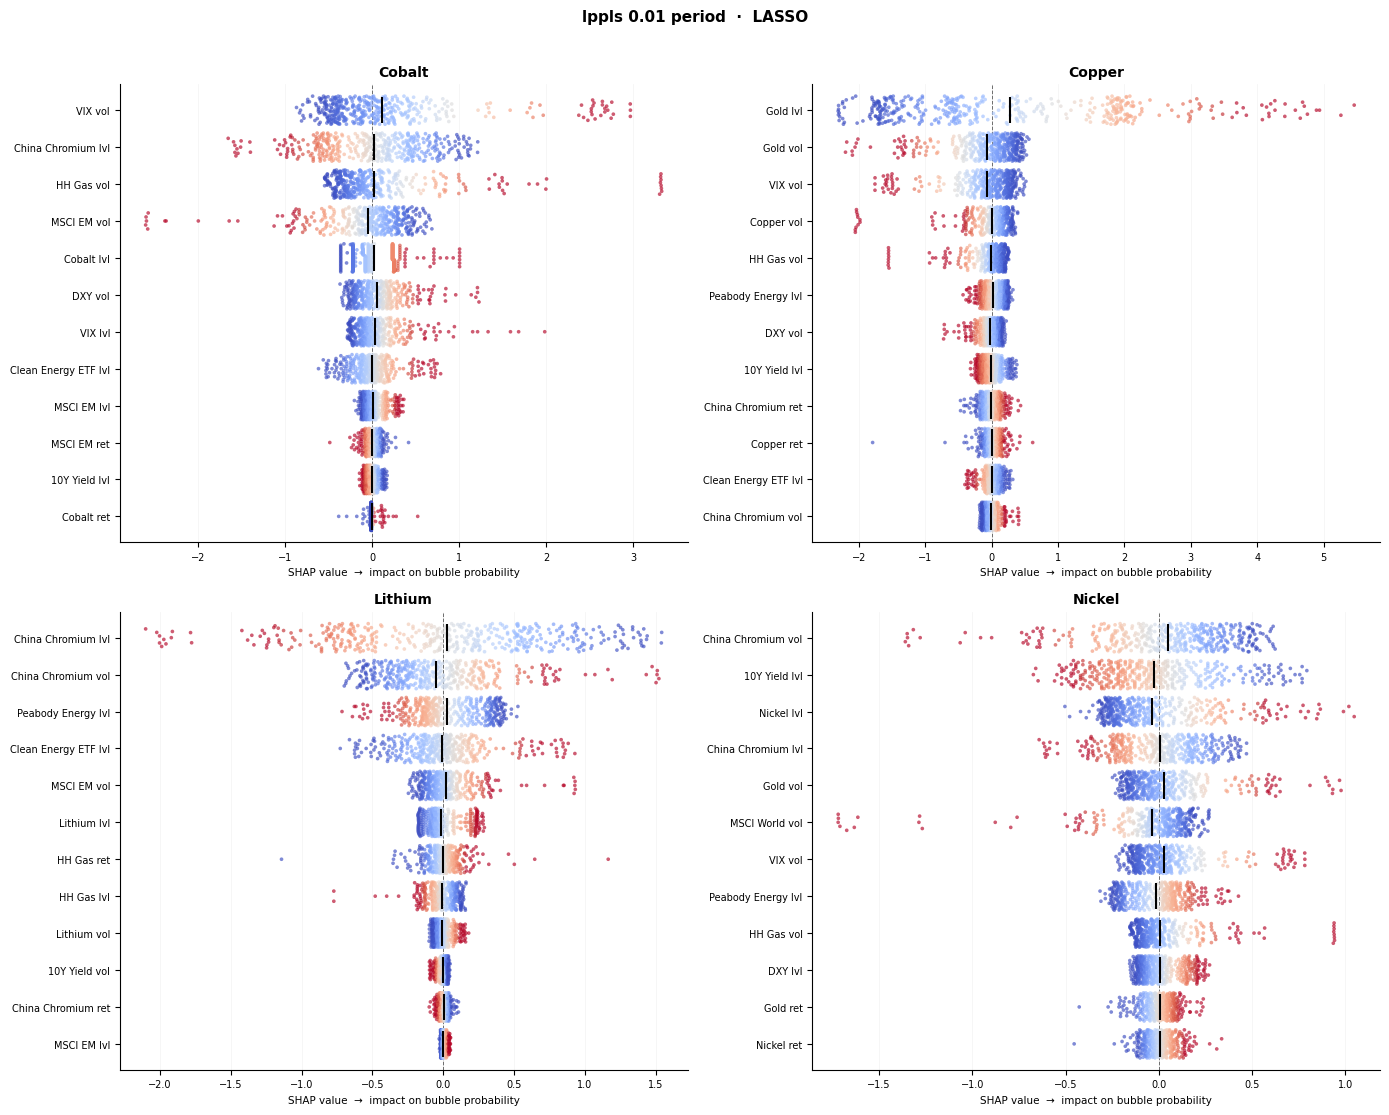

Saved → ../outputs/06_lppls_0.01_period_shap_lasso_global.png


In [50]:
# 3b. SHAP — global-best model (LASSO)
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}_global.png')


Computing SHAP: best-per-metal on lppls_0.01_period ...


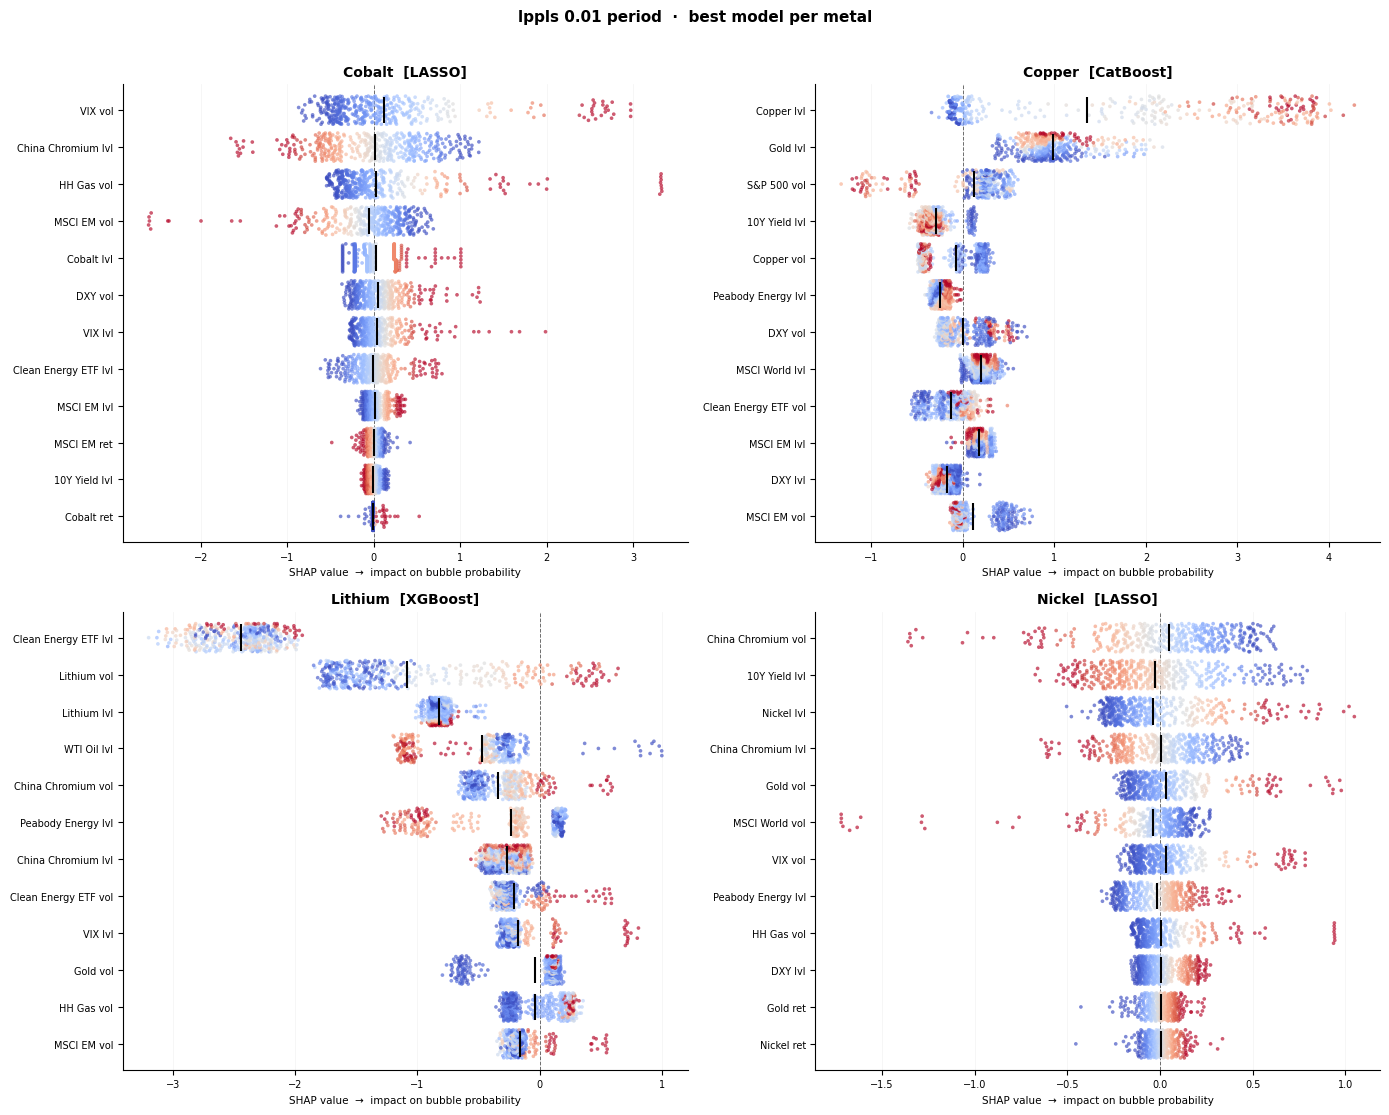

Saved → ../outputs/06_lppls_0.01_period_shap_best_per_metal.png


In [51]:
# 3c. SHAP — best model per metal
print(f'Computing SHAP: best-per-metal on {V} ...')
plot_shap_best_per_metal(V, C, f'../outputs/06_{V}_shap_best_per_metal.png')


---
## Section 4 — `cusum_smoothed`

`cusum_smoothed` applies a 5-day rolling mean to the CUSUM log-return statistic before thresholding, smoothing out day-to-day noise while retaining multi-day exceedance runs. Unlike the GSADF and LPPLS variants, it requires no distributional assumption or model fitting — it is a purely nonparametric control-chart signal. Models here are trained using the CUSUM-smoothed flag as the prediction target, enabling SHAP to reveal which market features most reliably precede CUSUM-identified stress periods.

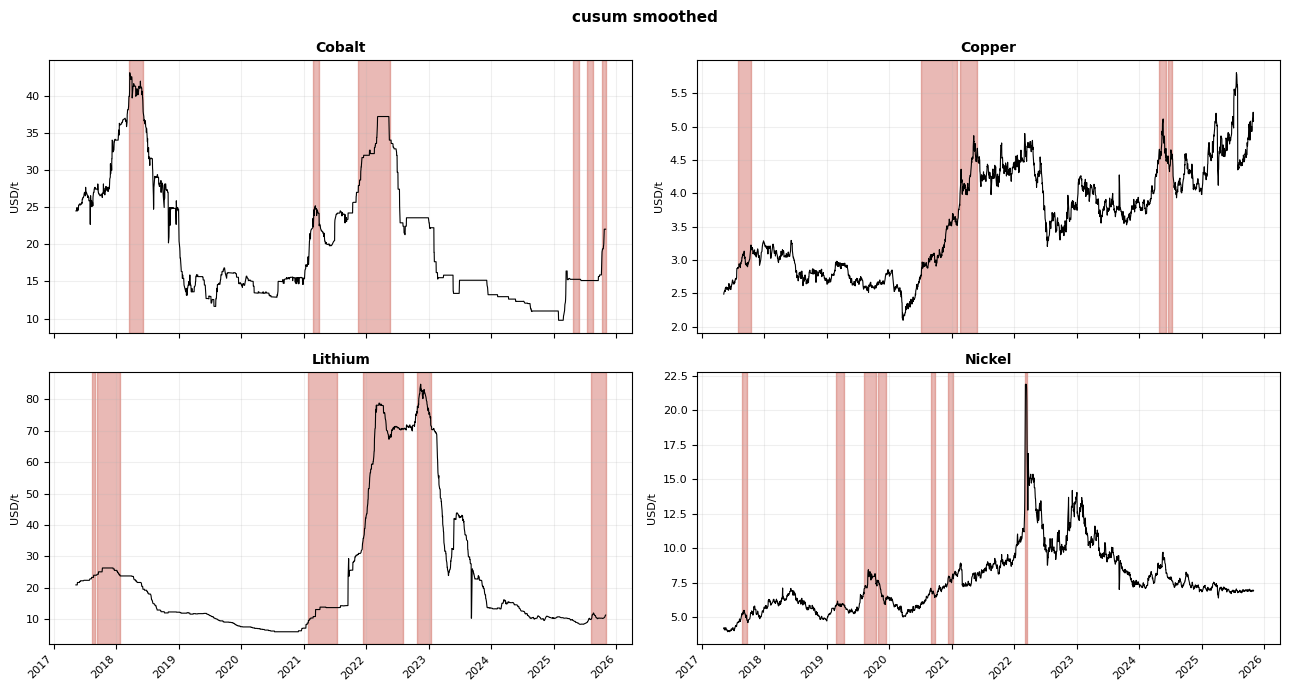

Saved → ../outputs/06_cusum_smoothed_bubbles.png


In [52]:
V = 'cusum_smoothed'
C = VARIANT_COLORS[V]

# 4a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on cusum_smoothed × 4 metals ...


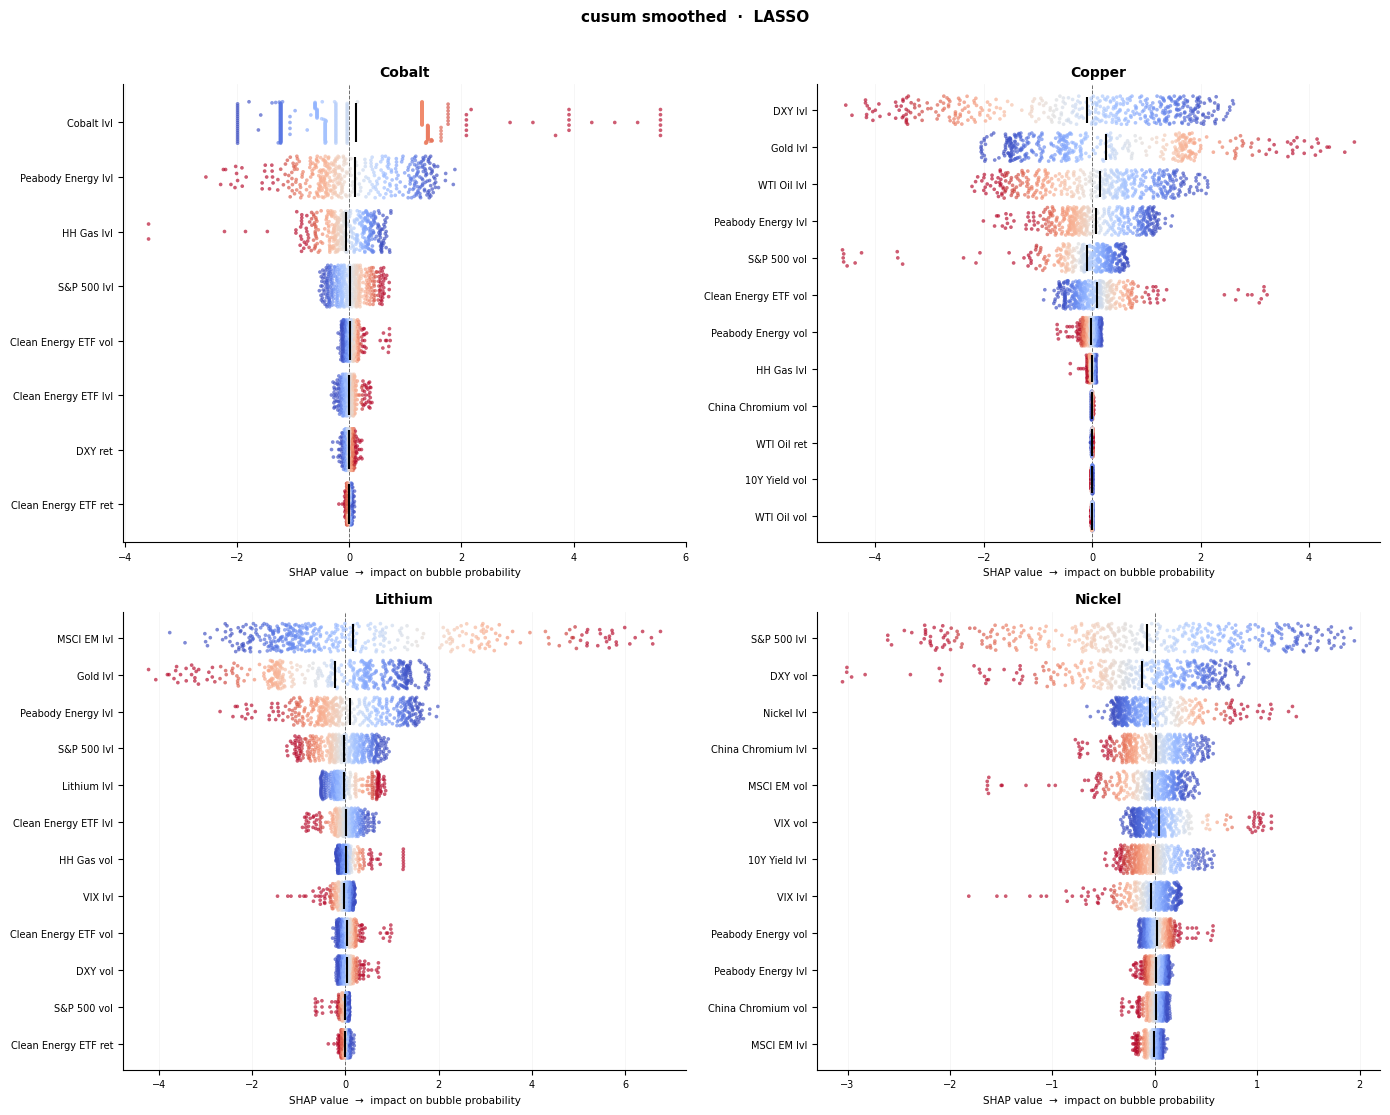

Saved → ../outputs/06_cusum_smoothed_shap_lasso_global.png


In [53]:
# 4b. SHAP — global-best model (LASSO)
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}_global.png')


Computing SHAP: best-per-metal on cusum_smoothed ...


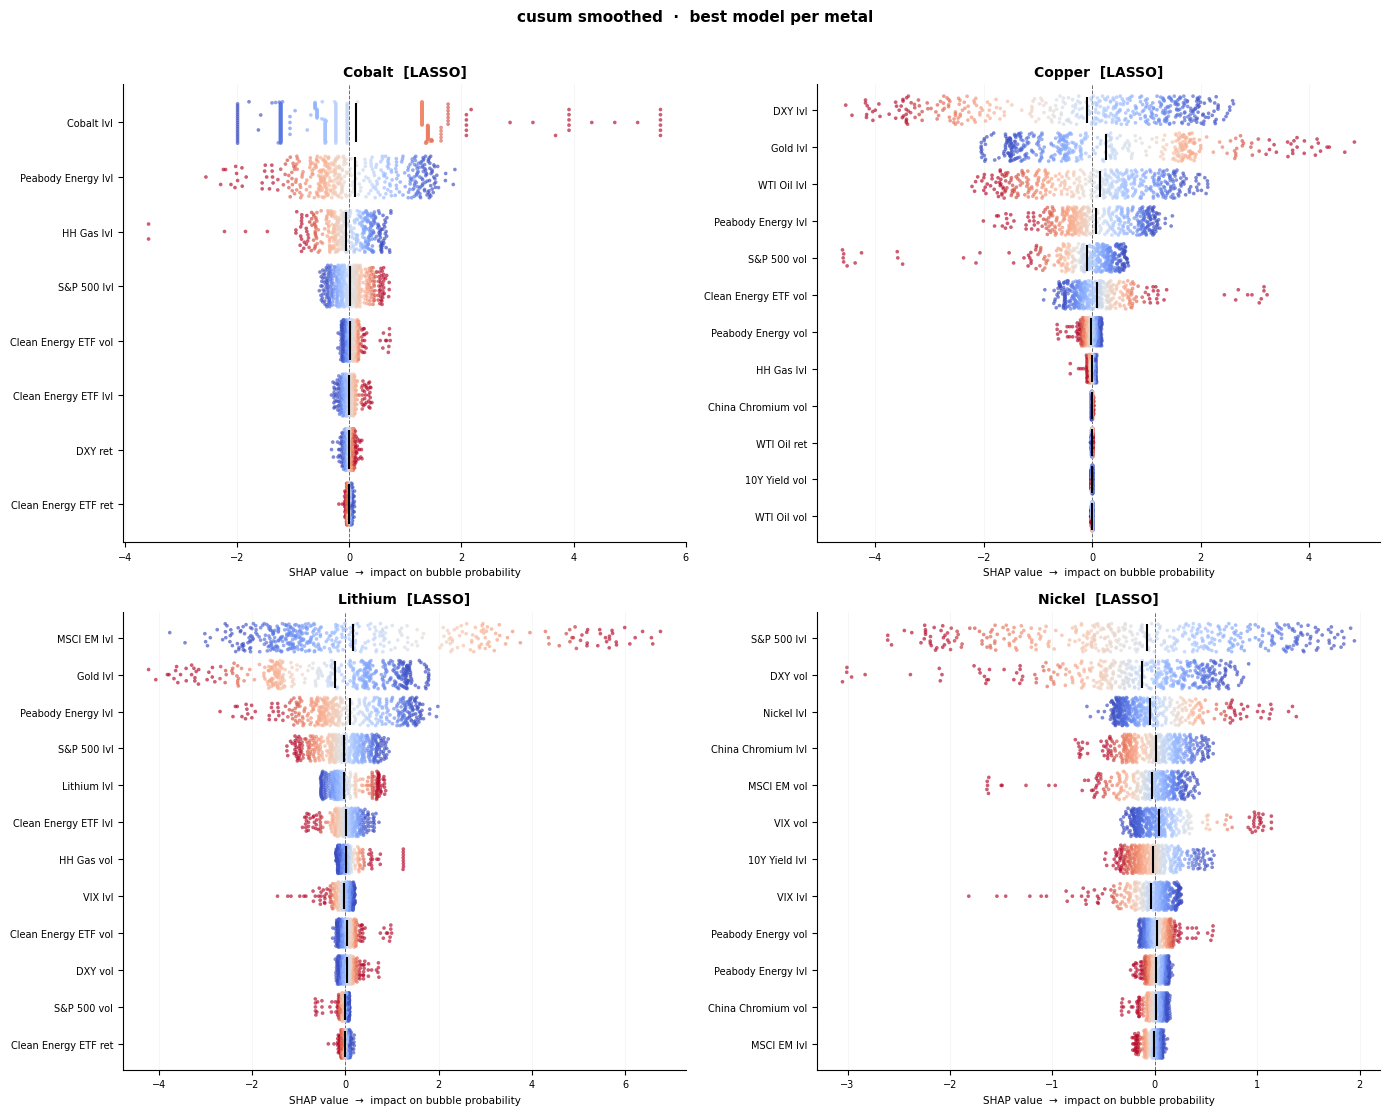

Saved → ../outputs/06_cusum_smoothed_shap_best_per_metal.png


In [54]:
# 4c. SHAP — best model per metal for cusum_smoothed
print(f'Computing SHAP: best-per-metal on {V} ...')
plot_shap_best_per_metal(V, C, f'../outputs/06_{V}_shap_best_per_metal.png')


---
## Summary — Cross-Variant SHAP Comparison (LASSO, all 4 variants × 4 metals)

Using LASSO consistently across all combinations allows a direct apples-to-apples comparison of which features matter most for each detection method.

Building cross-variant SHAP summary panel ...


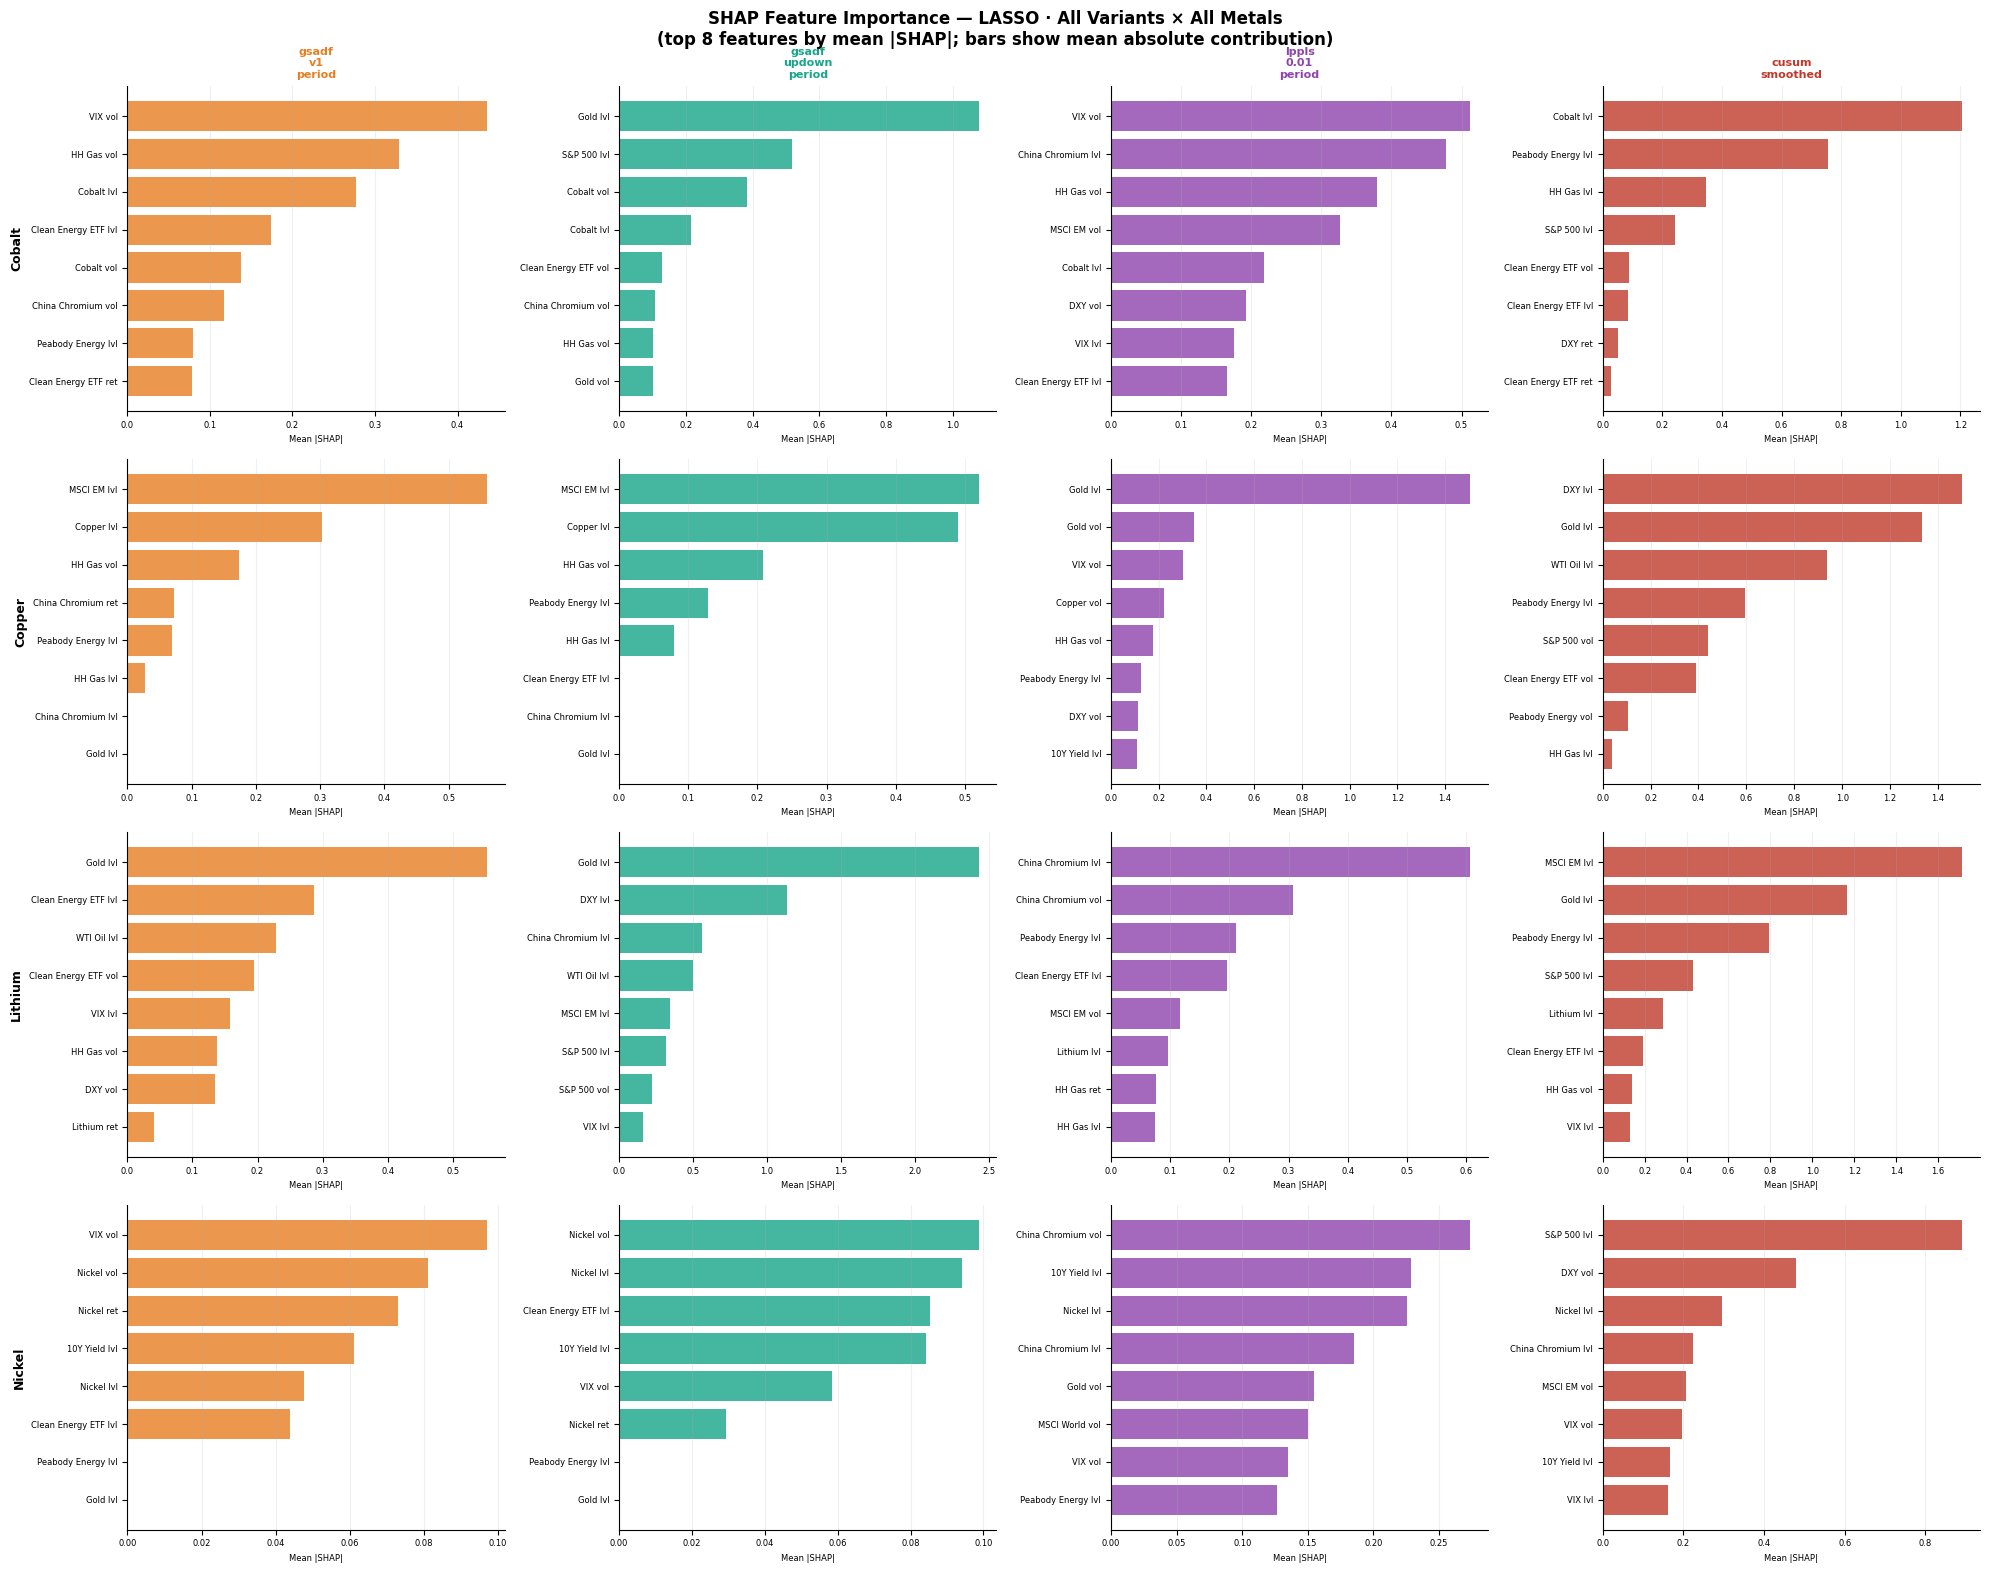

Saved → ../outputs/06_shap_crossvariant_summary.png

── All outputs ──
  06_gsadf_v1_period_bubbles.png
  06_gsadf_v1_period_shap_lasso_global.png
  06_gsadf_v1_period_shap_best_per_metal.png
  06_gsadf_updown_period_bubbles.png
  06_gsadf_updown_period_shap_lasso_global.png
  06_gsadf_updown_period_shap_best_per_metal.png
  06_lppls_0.01_period_bubbles.png
  06_lppls_0.01_period_shap_lasso_global.png
  06_lppls_0.01_period_shap_best_per_metal.png
  06_cusum_smoothed_bubbles.png
  06_cusum_smoothed_shap_lasso_global.png
  06_cusum_smoothed_shap_best_per_metal.png
  06_shap_crossvariant_summary.png


In [55]:
# 4-row × 4-col grid: rows = metals, cols = variants
# Each cell: horizontal bar chart (top-8 features by mean |SHAP|, LASSO model)
print('Building cross-variant SHAP summary panel ...')

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
metals_list = list(METALS.keys())

for col_i, v in enumerate(FOCUS_VARIANTS):
    for row_i, metal in enumerate(metals_list):
        ax = axes[row_i][col_i]
        try:
            sv, feat_names, X_te, _ = fit_and_shap(metal, v, GLOBAL_BEST_MODEL)
            sv        = np.array(sv)
            mean_abs  = np.abs(sv).mean(axis=0)
            idx       = [int(i) for i in np.argsort(mean_abs)[-8:][::-1]]
            labels    = [friendly_name(feat_names[i]) for i in idx]
            vals      = mean_abs[idx]
            ax.barh(labels[::-1], vals[::-1], color=VARIANT_COLORS[v], alpha=0.8)
            ax.tick_params(labelsize=6)
            ax.set_xlabel('Mean |SHAP|', fontsize=6)
        except Exception as e:
            ax.text(0.5, 0.5, str(e)[:60], ha='center', va='center',
                    transform=ax.transAxes, fontsize=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(axis='x', alpha=0.2)
        if row_i == 0:
            ax.set_title(v.replace('_', '\n'), fontsize=8, fontweight='bold',
                         color=VARIANT_COLORS[v])
        if col_i == 0:
            ax.set_ylabel(metal, fontsize=9, fontweight='bold')

plt.suptitle(
    'SHAP Feature Importance — LASSO · All Variants × All Metals\n'
    '(top 8 features by mean |SHAP|; bars show mean absolute contribution)',
    fontsize=12, fontweight='bold')
plt.tight_layout()
save_p = '../outputs/06_shap_crossvariant_summary.png'
plt.savefig(save_p, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved → {save_p}')

print('\n── All outputs ──')
for v in FOCUS_VARIANTS:
    print(f'  06_{v}_bubbles.png')
    print(f'  06_{v}_shap_lasso_global.png')
    print(f'  06_{v}_shap_best_per_metal.png')
print('  06_shap_crossvariant_summary.png')
